# TITLE


## Dataset Overview: Anime, Characters, Creators, Users

This dataset is organized into four macro categories that together describe the anime ecosystem from content to audience. The Anime category covers the titles themselves and how people interact with them. The `details` table holds core per-title metadata such as titles, formats, genres, airing dates, and platforms. The `stats` table captures aggregate engagement, including how many users are watching, completed, or dropped each title, along with score distributions. The `ratings` table contains individual user logs that record per-user watch status and numeric ratings. The `recommendations` table links titles with "if you liked X, try Y" relationships that help surface similar shows.

The Characters category represents the cast and how they appear across shows. The `characters` table provides biographies, including identity, background, and notable traits. The `character_anime_works` table maps each character to the anime in which they appear and indicates whether their role is main or supporting. The `character_nicknames` table lists alternate names and fan-used monikers, reflecting how communities refer to characters in practice.

The Creators category documents the people who make anime happen and their credited work. The `person_details` table profiles industry professionals such as voice actors, directors, and animators. The `person_anime_works` table records production credits, specifying who worked on which anime and in what capacity. The `person_voice_works` table focuses on voice acting, showing who voiced which characters and in which language. The `person_alternate_names` table captures stage names and alternative spellings used by creators.

The Users category describes the audience, their habits, and their preferences. The `profiles` table summarizes user demographics and viewing behavior, including how much they have watched, completed, dropped, placed on hold, or plan to watch. The `favs` table highlights user favorites, identifying the anime and characters individual users love most. Taken together, these four categories offer a coherent map of the dataset: titles and engagement live under Anime; personality and presence live under Characters; production roles and credits live under Creators; and audience behavior and preferences live under Users.


## The Anime Phenomenon

This dataset represents one of the most extensive collections of anime industry data:  
aggregating **330k users** across **30k titles** spanning **20+ countries** with more than **10 languages** being used and **450k+ staff and productions** credits across key roles.  
The dataset provides unprecedented insight into the global anime ecosystem, from production to consumption leading us to rich explorations:

**About the Industry:**

- What makes an anime successful?
- Do certain voice actors or studios consistently produce hits?
- How do genres trend over time?

**About Content:**

- Which characters resonate most with audiences?
- What types of anime get recommended together?
- Are there distinct anime "communities" or clusters?

**About Fans:**

- What predicts whether someone will complete or drop an anime?
- How do viewing patterns differ across user demographics?
- Can we build a recommendation system that understands taste?

But why so?

To answer a simple, yet not easy, question:  
**if I want to produce a top tier anime, what should I take care of?**

---


In [8]:
import sys
from pathlib import Path
from importlib import reload

sys.path.append(str(Path.cwd().parent))

import utils.graphs_utils as gu
reload(gu)

<module 'utils.graphs_utils' from 'c:\\Users\\Lorenzo\\OneDrive\\Desktop\\Adam_Aseglio_Bertola_HCI\\utils\\graphs_utils.py'>

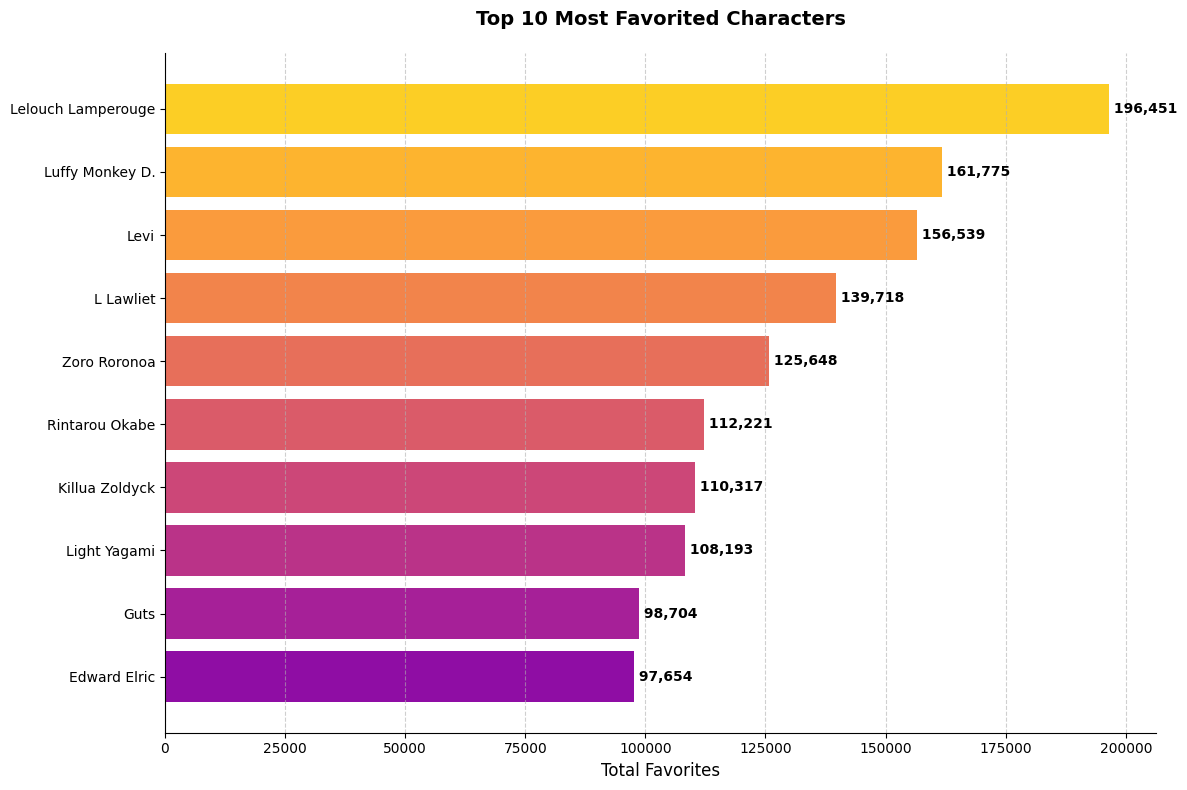

In [2]:
fig, ax = gu.top_n_most_favorited_characters()

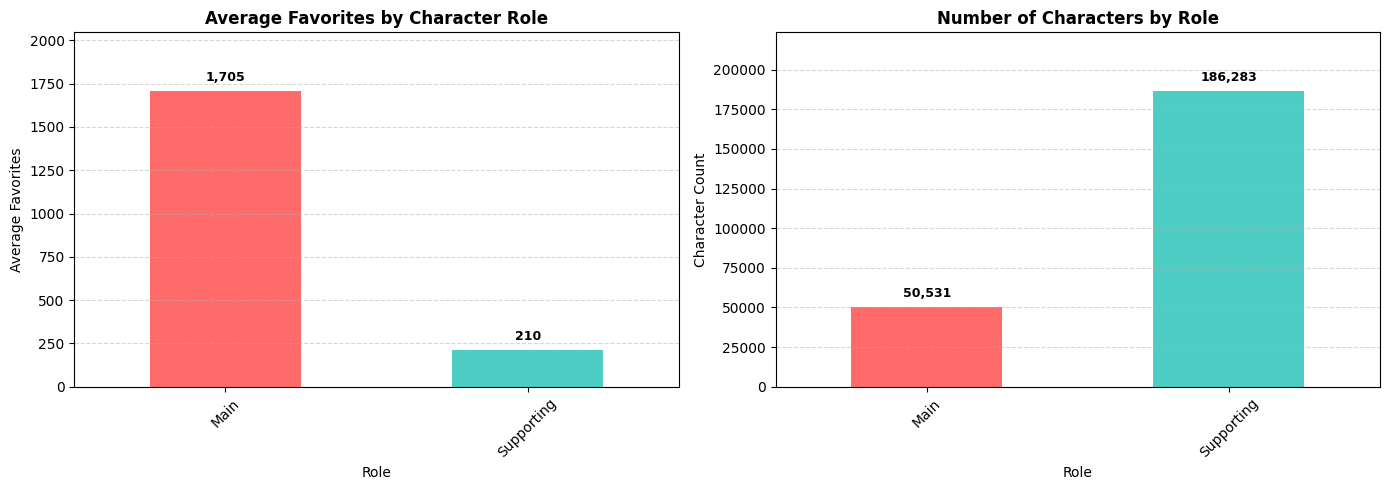

In [3]:
fig, ax = gu.character_popularity_by_role()

In [4]:
fig = gu.character_popularity_by_genre_bars()
fig.show()

## Global Distribution of Anime Users Over Time

### Interactive Choropleth Map with Plotly

This animated map shows how anime users have joined from different countries over time, **year by year** from 2004 to 2025.

In [2]:
import sys
sys.path.append('../utils')
from graphs_utils import load_and_prepare_profiles

# Carico e preparo il dataset profiles
profiles_df = load_and_prepare_profiles()

### Understanding the Logarithmic Color Scale

To better visualize countries with varying user populations, we use a **logarithmic scale** for the color gradient. This transformation makes it easier to distinguish between countries with lower user counts while still showing the dominance of major markets.

**Why logarithmic?**
- **Without log scale**: Countries with 50,000+ users dominate the entire color range, making countries with 10-1,000 users appear nearly identical.
- **With log scale**: Each order of magnitude (10 → 100 → 1,000 → 10,000) gets equal visual weight, revealing growth patterns in emerging markets.

**What you'll see:**
- Countries are colored by **log₁₀(Total Users + 1)**
- Hover over any country to see the **actual user count** (not logarithmic)
- The color scale ranges from **Turbo** (high contrast) for better differentiation

This approach highlights both the anime superpowers (USA, Japan, etc.) and emerging communities worldwide.

In [10]:
# Force reload del modulo graphs_utils per applicare le correzioni
import sys
import importlib
if 'graphs_utils' in sys.modules:
    importlib.reload(sys.modules['graphs_utils'])

In [ ]:
import plotly.express as px  # Importo px per la funzione create_animated_map
from graphs_utils import prepare_country_data, create_animated_map

# Preparo i dati aggregati per paese e anno
country_year_counts = prepare_country_data(profiles_df)

# Statistiche sui dati
print("Dati aggregati:")
print(f"Paesi unici prima della normalizzazione: {profiles_df['location'].nunique()}")
print(f"Paesi unici dopo la normalizzazione: {country_year_counts['country'].nunique()}")
print(f"\nNumero totale di record: {len(country_year_counts)}")
print(f"Anni disponibili: {sorted(country_year_counts['year_label'].unique())}")

# Creo e mostro la mappa animata
fig = create_animated_map(country_year_counts)
fig.show()

Dati aggregati:
Paesi unici prima della normalizzazione: 22
Paesi unici dopo la normalizzazione: 16

Numero totale di record: 324
Anni disponibili: [np.int32(2004), np.int32(2005), np.int32(2006), np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


NameError: name 'px' is not defined

**Key Insights from the Global Distribution Map:**

1. **North America dominates the Western market** - The United States shows the deepest color intensity throughout the timeline, indicating the largest anime fanbase outside Asia. Canada follows as a secondary hub, revealing that English-language accessibility and cultural openness to Japanese media drive North American adoption.

2. **Europe shows steady growth but regional variation** - Countries like France, Germany, and the UK display consistent mid-range user counts, while Eastern European nations remain lighter. This suggests Western Europe has embraced anime culture more rapidly, possibly due to earlier access to localized content and anime conventions.

3. **Latin America is an emerging powerhouse** - Brazil, Mexico, and Argentina show notable color intensity, especially in recent years. The growth acceleration suggests that Spanish and Portuguese-speaking markets are untapped opportunities for producers seeking international expansion.

4. **Asia-Pacific remains the cultural origin** - Japan naturally shows deep color throughout (though many Japanese users may use domestic platforms), while nearby countries like South Korea, Thailand, and the Philippines display strong engagement. Cultural proximity and shared storytelling traditions explain this regional clustering.

5. **Middle East and Africa remain underrepresented** - These regions show minimal color intensity across all years, indicating either limited platform access, language barriers, or cultural/regulatory constraints. This represents a significant gap in global anime penetration.

6. **Exponential growth from 2010 onwards** - The logarithmic scale reveals that user counts exploded after 2010, likely driven by streaming platforms (Crunchyroll, Netflix) making anime more accessible globally. Earlier years (2004-2009) show modest, concentrated growth in traditional markets.

**Strategic Implications:**

- **Localization matters**: Success in France, Latin America, and Southeast Asia correlates with dubbed/subtitled content availability
- **Streaming is the catalyst**: The post-2010 surge aligns with the rise of legal streaming platforms
- **Untapped markets**: Africa, Middle East, and parts of Eastern Europe present opportunities if cultural and distribution barriers are addressed
- **Cultural adjacency drives adoption**: Geographic/cultural proximity to Japan predicts stronger engagement (Korea, Southeast Asia vs distant regions)